# IND320 Project Part 2

## Reservoir Data Analysis
This notebook documents Part 2 of the IND320 project, focusing on data retrieval, processing, storage, and visualization using APIs, Apache Spark, Cassandra, and MongoDB.

The project builds on Part 1 by replacing local CSV files with API connections and database solutions, while further developing the Streamlit application.

## 1. Importing reservoir data from the NVE API

The reservoir dataset is retrieved directly from the NVE API instead of a local CSV file. The API response is converted from JSON into a Pandas DataFrame containing 14,913 observations and 11 columns. The first five rows are displayed to inspect the data before further processing and visualization.

In [ ]:
import pandas as pd
import requests
import matplotlib.pyplot as plt

# NVE API endpoint for Norwegian reservoir statistics
url = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData"

# Request data directly from the API
response = requests.get(url, timeout=60)
response.raise_for_status()

# Convert the JSON response into a Pandas DataFrame
df = pd.DataFrame(response.json())

# Display the dataset
print("Dataset shape:", df.shape)
display(df.head())

## 2. Renaming the columns

The original dataset contains Norwegian column names. To make the dataset easier to understand and work with, the columns are renamed using clear English names.

In [ ]:
#rename the original norwegian columns to clear english names
df = df.rename(columns={
    "dato_Id": "date",
    "omrType": "area_type",
    "omrnr": "area_number",
    "iso_aar": "year",
    "iso_uke": "week",
    "fyllingsgrad": "fill_level",
    "kapasitet_TWh": "capacity_TWh",
    "fylling_TWh": "stored_energy_TWh",
    "neste_Publiseringsdato": "next_publication_date",
    "fyllingsgrad_forrige_uke": "fill_level_previous_week",
    "endring_fyllingsgrad": "change_in_fill_level"
})

#check that the new column names were applied correctly
df.head()

## 3. Exploring the dataset

Before creating visualizations, it is useful to examine the size, structure and data types of the dataset. This provides an overview of the available variables and helps identify how the data should be handled in the following analysis.

In [ ]:
#show the number of rows and columns in the dataset
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

#inspect column names, data types and missing values
df.info()

## 4. Displaying the data

The dataset retrieved from the NVE API contains 14,913 observations and 11 variables. To get a clearer overview of the reservoir data, the first ten observations are displayed below.

In [ ]:
#display the first ten observations for a closer look at the data
display(df.head(10))

## 5. Visualizing individual columns

To better understand the dataset, the relevant numerical variables are visualized separately. The data is sorted by date before plotting so that changes over time are displayed chronologically.

In [ ]:
#convert the date column to datetime and sort the data chronologically
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date")

df.head()

In [ ]:
#select the numerical reservoir variables to visualize
numeric_columns = [
    "fill_level",
    "capacity_TWh",
    "stored_energy_TWh",
    "fill_level_previous_week",
    "change_in_fill_level"
]

#plot each numerical variable separately for every reservoir area
for column in numeric_columns:
    plt.figure(figsize=(10, 5))

    for area in sorted(df["area_number"].unique()):
        area_data = df[df["area_number"] == area]

        plt.plot(
            area_data["date"],
            area_data[column],
            label=f"Area {area}"
        )

    #add labels, title, legend and grid to each plot
    plt.xlabel("Date")
    plt.ylabel(column)
    plt.title(column.replace("_", " ").title())
    plt.legend()
    plt.grid(True)
    plt.show()

## 6. Visualizing all numerical columns together

Since the numerical variables have different units and scales, they are normalized before being plotted together. This makes it possible to compare their development over time in a single figure.

In [ ]:
#select the numerical variables to compare
columns_to_plot = [
    "fill_level",
    "capacity_TWh",
    "stored_energy_TWh",
    "fill_level_previous_week",
    "change_in_fill_level"
]

# use national reservoir data (Area 0) for comparison
plot_data = df[df["area_number"] == 0].set_index("date")[columns_to_plot].sort_index()

# Handle constant variables to avoid division by zero
ranges = plot_data.max() - plot_data.min()
normalized_df = (plot_data - plot_data.min()) / ranges.replace(0, 1)

#plot all normalized variables together
plt.figure(figsize=(12, 6))

for column in normalized_df.columns:
    plt.plot(
        normalized_df.index,
        normalized_df[column],
        label=column.replace("_", " ").title()
    )

#add labels, title, legend and grid to the plot
plt.xlabel("Date")
plt.ylabel("Normalized value")
plt.title("Normalized Reservoir Variables Over Time")
plt.legend()
plt.grid(True)
plt.show()

## 7. Setting up and testing Apache Spark

In [ ]:
import os

# Load the Cassandra Connector when Spark starts
os.environ["PYSPARK_SUBMIT_ARGS"] = (
    "--packages com.datastax.spark:spark-cassandra-connector_2.12:3.5.1 "
    "pyspark-shell"
)

from pyspark.sql import SparkSession

# Create a Spark session connected to local Cassandra
spark = (
    SparkSession.builder
    .appName("IND320 Part 2")
    .master("local[*]")
    .config("spark.cassandra.connection.host", "127.0.0.1")
    .config("spark.cassandra.connection.port", "9042")
    .config("spark.cassandra.connection.localDC", "datacenter1")
    .getOrCreate()
)

# Verify the connector configuration
print("Spark version:", spark.version)
print(
    "Configured packages:",
    spark.sparkContext.getConf().get("spark.jars.packages", "NOT SET")
)


In [ ]:
# Test the Spark connection to our IND320 Cassandra database
cassandra_test = (
    spark.read
    .format("org.apache.spark.sql.cassandra")
    .options(keyspace="ind320", table="connection_test")
    .load()
)

# Display the test data
cassandra_test.show(truncate=False)

In [ ]:
# Check the Spark configuration and loaded connector files
print(
    "Configured packages:",
    spark.sparkContext.getConf().get("spark.jars.packages", "NOT SET")
)

print(
    "Loaded JAR files:",
    spark.sparkContext._jsc.sc().listJars().toString()
)

## 8. Connecting to MongoDB Atlas

In [1]:
from urllib.parse import urlsplit
import os
from dotenv import load_dotenv

load_dotenv(".env", override=True)

uri = os.getenv("MONGODB_URI", "")
print("MongoDB hostname:", urlsplit(uri).hostname)

MongoDB hostname: ind320-cluster.wwxppks.mongodb.net


In [2]:
import dns.resolver

# Use Google's public DNS server for this Python session
resolver = dns.resolver.Resolver(configure=False)
resolver.nameservers = ["8.8.8.8"]
resolver.timeout = 5
resolver.lifetime = 15

# Test DNS resolution for MongoDB Atlas
records = resolver.resolve(
    "_mongodb._tcp.ind320-cluster.wwxppks.mongodb.net",
    "SRV"
)

for record in records:
    print(record)

dns.resolver.default_resolver = resolver
dns.resolver.get_default_resolver = lambda: resolver

0 0 27017 ac-yyotwue-shard-00-01.wwxppks.mongodb.net.
0 0 27017 ac-yyotwue-shard-00-02.wwxppks.mongodb.net.
0 0 27017 ac-yyotwue-shard-00-00.wwxppks.mongodb.net.


In [3]:
import os
from dotenv import load_dotenv
from pymongo import MongoClient

# Load the MongoDB connection string from the local .env file
load_dotenv(".env", override=True)

mongodb_uri = os.getenv("MONGODB_URI")

if not mongodb_uri:
    raise ValueError("MONGODB_URI was not found in the .env file.")

# Connect to MongoDB Atlas
client = MongoClient(mongodb_uri, serverSelectionTimeoutMS=10000)

# Test the connection
client.admin.command("ping")

print("Successfully connected to MongoDB Atlas!")

Successfully connected to MongoDB Atlas!


In [4]:
import os
import requests
from dotenv import load_dotenv

# Load the ENTSO-E API token
load_dotenv(".env", override=True)
token = os.getenv("ENTSOE_API_TOKEN")

if not token:
    raise ValueError("ENTSOE_API_TOKEN was not found in .env")

# Retrieve actual electricity consumption for NO1
url = "https://web-api.tp.entsoe.eu/api"

params = {
    "securityToken": token,
    "documentType": "A65",
    "processType": "A16",
    "outBiddingZone_Domain": "10YNO-1--------2",
    "periodStart": "202610090000",
    "periodEnd": "202610100000"
}

response = requests.get(url, params=params, timeout=30)

print("HTTP status:", response.status_code)
print("Response preview:")
print(response.text[:400])

HTTP status: 200
Response preview:
<?xml version="1.0" encoding="utf-8"?>
<GL_MarketDocument xmlns="urn:iec62325.351:tc57wg16:451-6:generationloaddocument:3:0">
  <mRID>3454cafd7e654618bbd82a32d7655c14</mRID>
  <revisionNumber>1</revisionNumber>
  <type>A65</type>
  <process.processType>A16</process.processType>
  <sender_MarketParticipant.mRID codingScheme="A01">10X1001A1001A450</sender_MarketParticipant.mRID>
  <sender_MarketPart


## 9. ENTSO-E Cross-Border Electricity Flows

This section retrieves cross-border electricity flow data
between Norway and neighbouring countries using the ENTSO-E API.

The data will be processed using Apache Spark and stored
in Cassandra before further analysis and visualization.

In [5]:

import os
import requests
import xml.etree.ElementTree as ET
from dotenv import load_dotenv

# Load the API token securely
load_dotenv(".env", override=True)
token = os.getenv("ENTSOE_API_TOKEN")

if not token:
    raise ValueError("ENTSOE_API_TOKEN was not found in .env")

# ENTSO-E bidding zone identifiers
NO2 = "10YNO-2--------T"
DK1 = "10YDK-1--------W"

url = "https://web-api.tp.entsoe.eu/api"

# Test one day of cross-border flows in both directions
directions = {
    "Export NO2 to DK1": (NO2, DK1),
    "Import DK1 to NO2": (DK1, NO2)
}

for direction, (out_domain, in_domain) in directions.items():

    params = {
        "securityToken": token,
        "documentType": "A11",
        "out_Domain": out_domain,
        "in_Domain": in_domain,
        "periodStart": "202510010000",
        "periodEnd": "202510020000"
    }

    response = requests.get(url, params=params, timeout=30)

    print(f"\n{direction}")
    print("HTTP status:", response.status_code)

    response.raise_for_status()

    # Parse the XML response
    root = ET.fromstring(response.content)

    if root.tag.endswith("Acknowledgement_MarketDocument"):
        print("API message:", response.text[:500])
        continue

    time_series = root.findall(".//{*}TimeSeries")
    points = root.findall(".//{*}Point")

    print("Time series:", len(time_series))
    print("Data points:", len(points))

    # Display a few example measurements
    for point in points[:5]:
        position = point.findtext("{*}position")
        quantity = point.findtext("{*}quantity")
        print(f"Position {position}: {quantity} MW")



Export NO2 to DK1
HTTP status: 200
Time series: 1
Data points: 96
Position 1: 1069.79 MW
Position 2: 1070.04 MW
Position 3: 1083.06 MW
Position 4: 1261.11 MW
Position 5: 1321.06 MW

Import DK1 to NO2
HTTP status: 200
Time series: 1
Data points: 1
Position 1: 0 MW


In [6]:

import pandas as pd
from datetime import datetime, timedelta

# Convert ENTSO-E API responses into a structured DataFrame
flow_rows = []

for direction, (out_domain, in_domain) in directions.items():

    params = {
        "securityToken": token,
        "documentType": "A11",
        "out_Domain": out_domain,
        "in_Domain": in_domain,
        "periodStart": "202510010000",
        "periodEnd": "202510020000"
    }

    response = requests.get(url, params=params, timeout=30)
    response.raise_for_status()
    root = ET.fromstring(response.content)

    for series in root.findall(".//{*}TimeSeries"):

        curve_type = series.findtext("{*}curveType")

        for period in series.findall("{*}Period"):

            start_text = period.findtext(
                "{*}timeInterval/{*}start"
            )
            end_text = period.findtext(
                "{*}timeInterval/{*}end"
            )
            resolution = period.findtext("{*}resolution")

            start_time = datetime.fromisoformat(
                start_text.replace("Z", "+00:00")
            )

            print(
                direction,
                "| Resolution:", resolution,
                "| Curve:", curve_type,
                "| Period:", start_text, "to", end_text
            )

            # Convert the time resolution into minutes
            resolution_minutes = {
                "PT15M": 15,
                "PT30M": 30,
                "PT60M": 60
            }.get(resolution)

            if resolution_minutes is None:
                raise ValueError(
                    f"Unsupported resolution: {resolution}"
                )

            for point in period.findall("{*}Point"):
                position = int(
                    point.findtext("{*}position")
                )
                quantity = float(
                    point.findtext("{*}quantity")
                )

                timestamp = start_time + timedelta(
                    minutes=(position - 1) * resolution_minutes
                )

                flow_rows.append({
                    "timestamp": timestamp,
                    "connection": "NO2-DK1",
                    "direction": direction,
                    "power_MW": quantity,
                    "resolution_minutes": resolution_minutes
                })

flow_df = pd.DataFrame(flow_rows)

# Sort and inspect the retrieved data
flow_df = flow_df.sort_values(
    ["timestamp", "direction"]
).reset_index(drop=True)

display(flow_df.head(10))

print("\nNumber of rows:", len(flow_df))
print("\nRows per direction:")
print(flow_df.groupby("direction").size())


Export NO2 to DK1 | Resolution: PT15M | Curve: A03 | Period: 2025-10-01T00:00Z to 2025-10-02T00:00Z
Import DK1 to NO2 | Resolution: PT15M | Curve: A03 | Period: 2025-10-01T00:00Z to 2025-10-02T00:00Z


,timestamp,connection,direction,power_MW,resolution_minutes
0,2025-10-01 00:00:00+00:00,NO2-DK1,Export NO2 to DK1,1069.79,15
1,2025-10-01 00:00:00+00:00,NO2-DK1,Import DK1 to NO2,0.00,15
2,2025-10-01 00:15:00+00:00,NO2-DK1,Export NO2 to DK1,1070.04,15
3,2025-10-01 00:30:00+00:00,NO2-DK1,Export NO2 to DK1,1083.06,15
4,2025-10-01 00:45:00+00:00,NO2-DK1,Export NO2 to DK1,1261.11,15
5,2025-10-01 01:00:00+00:00,NO2-DK1,Export NO2 to DK1,1321.06,15
6,2025-10-01 01:15:00+00:00,NO2-DK1,Export NO2 to DK1,1510.88,15
7,2025-10-01 01:30:00+00:00,NO2-DK1,Export NO2 to DK1,1612.13,15
8,2025-10-01 01:45:00+00:00,NO2-DK1,Export NO2 to DK1,1533.02,15
9,2025-10-01 02:00:00+00:00,NO2-DK1,Export NO2 to DK1,1327.15,15



Number of rows: 97

Rows per direction:
direction
Export NO2 to DK1    96
Import DK1 to NO2     1
dtype: int64


In [7]:

# Expand A03 variable-sized blocks to 15-minute intervals

day_start = pd.Timestamp("2025-10-01T00:00:00Z")
day_end = pd.Timestamp("2025-10-02T00:00:00Z")

full_times = pd.date_range(
    start=day_start,
    end=day_end,
    freq="15min",
    inclusive="left"
)

expanded_data = []

for direction, group in flow_df.groupby("direction"):

    group = group.sort_values("timestamp").set_index("timestamp")

    # Ensure the first block starts at the beginning of the day
    if group.index[0] != day_start:
        raise ValueError(f"Unexpected first timestamp: {direction}")

    # A03 values remain constant until the next reported point
    expanded = group.reindex(full_times, method="ffill")

    expanded["timestamp"] = expanded.index
    expanded["direction"] = direction

    expanded_data.append(expanded.reset_index(drop=True))

flow_full_df = pd.concat(
    expanded_data,
    ignore_index=True
).sort_values(["timestamp", "direction"]).reset_index(drop=True)

# Convert power (MW) into energy (MWh) per 15-minute interval
flow_full_df["energy_MWh"] = (
    flow_full_df["power_MW"] * 15 / 60
)

print("Total rows:", len(flow_full_df))
print("\nRows per direction:")
print(flow_full_df.groupby("direction").size())

print("\nTotal energy (MWh):")
print(flow_full_df.groupby("direction")["energy_MWh"].sum())

display(flow_full_df.head(10))


Total rows: 192

Rows per direction:
direction
Export NO2 to DK1    96
Import DK1 to NO2    96
dtype: int64

Total energy (MWh):
direction
Export NO2 to DK1    35976.6525
Import DK1 to NO2        0.0000
Name: energy_MWh, dtype: float64


,connection,direction,power_MW,resolution_minutes,timestamp,energy_MWh
0,NO2-DK1,Export NO2 to DK1,1069.79,15,2025-10-01 00:00:00+00:00,267.4475
1,NO2-DK1,Import DK1 to NO2,0.00,15,2025-10-01 00:00:00+00:00,0.0000
2,NO2-DK1,Export NO2 to DK1,1070.04,15,2025-10-01 00:15:00+00:00,267.5100
3,NO2-DK1,Import DK1 to NO2,0.00,15,2025-10-01 00:15:00+00:00,0.0000
4,NO2-DK1,Export NO2 to DK1,1083.06,15,2025-10-01 00:30:00+00:00,270.7650
5,NO2-DK1,Import DK1 to NO2,0.00,15,2025-10-01 00:30:00+00:00,0.0000
6,NO2-DK1,Export NO2 to DK1,1261.11,15,2025-10-01 00:45:00+00:00,315.2775
7,NO2-DK1,Import DK1 to NO2,0.00,15,2025-10-01 00:45:00+00:00,0.0000
8,NO2-DK1,Export NO2 to DK1,1321.06,15,2025-10-01 01:00:00+00:00,330.2650
9,NO2-DK1,Import DK1 to NO2,0.00,15,2025-10-01 01:00:00+00:00,0.0000


In [8]:

import pandas as pd
import requests
import xml.etree.ElementTree as ET

def fetch_cross_border_flow(out_domain, in_domain, direction,
                            period_start, period_end):

    params = {
        "securityToken": token,
        "documentType": "A11",
        "out_Domain": out_domain,
        "in_Domain": in_domain,
        "periodStart": period_start,
        "periodEnd": period_end
    }

    response = requests.get(url, params=params, timeout=60)
    response.raise_for_status()
    root = ET.fromstring(response.content)

    if root.tag.endswith("Acknowledgement_MarketDocument"):
        raise ValueError(f"ENTSO-E returned: {response.text[:500]}")

    rows = []

    for series in root.findall(".//{*}TimeSeries"):
        curve_type = series.findtext("{*}curveType")

        for period in series.findall("{*}Period"):

            start = pd.to_datetime(
                period.findtext("{*}timeInterval/{*}start"),
                utc=True
            )
            end = pd.to_datetime(
                period.findtext("{*}timeInterval/{*}end"),
                utc=True
            )

            resolution = period.findtext("{*}resolution")
            minutes = {
                "PT15M": 15,
                "PT30M": 30,
                "PT60M": 60
            }.get(resolution)

            if minutes is None:
                raise ValueError(f"Unknown resolution: {resolution}")

            timestamps = pd.date_range(
                start, end, freq=f"{minutes}min",
                inclusive="left"
            )

            values = {}
            for point in period.findall("{*}Point"):
                position = int(point.findtext("{*}position"))
                quantity = float(point.findtext("{*}quantity"))

                timestamp = start + pd.Timedelta(
                    minutes=(position - 1) * minutes
                )
                values[timestamp] = quantity

            power = pd.Series(values, dtype=float)

            # A03: each value remains valid until the next point
            if curve_type == "A03":
                power = power.reindex(timestamps).ffill()
            else:
                power = power.reindex(timestamps)

            if power.isna().any():
                raise ValueError(
                    f"Missing measurements for {direction}"
                )

            for timestamp, mw in power.items():
                rows.append({
                    "timestamp": timestamp,
                    "connection": "NO2-DK1",
                    "direction": direction,
                    "power_MW": mw,
                    "energy_MWh": mw * minutes / 60
                })

    if not rows:
        raise ValueError(f"No flow data returned for {direction}")

    return pd.DataFrame(rows)


# Retrieve January 2025 in both directions
monthly_frames = []

for direction, (out_domain, in_domain) in directions.items():
    df = fetch_cross_border_flow(
        out_domain,
        in_domain,
        direction,
        "202501010000",
        "202502010000"
    )
    monthly_frames.append(df)

january_df = pd.concat(
    monthly_frames, ignore_index=True
).sort_values(["timestamp", "direction"])

print("Total rows:", len(january_df))
print("\nRows per direction:")
print(january_df.groupby("direction").size())

print("\nTotal energy (MWh):")
print(january_df.groupby("direction")["energy_MWh"].sum())

display(january_df.head(10))


Total rows: 1488

Rows per direction:
direction
Export NO2 to DK1    744
Import DK1 to NO2    744
dtype: int64

Total energy (MWh):
direction
Export NO2 to DK1    762042.750
Import DK1 to NO2     91769.725
Name: energy_MWh, dtype: float64


,timestamp,connection,direction,power_MW,energy_MWh
0,2025-01-01 00:00:00+00:00,NO2-DK1,Export NO2 to DK1,0.0000,0.0000
744,2025-01-01 00:00:00+00:00,NO2-DK1,Import DK1 to NO2,1603.9600,1603.9600
1,2025-01-01 01:00:00+00:00,NO2-DK1,Export NO2 to DK1,0.0000,0.0000
745,2025-01-01 01:00:00+00:00,NO2-DK1,Import DK1 to NO2,1585.1300,1585.1300
2,2025-01-01 02:00:00+00:00,NO2-DK1,Export NO2 to DK1,0.0000,0.0000
746,2025-01-01 02:00:00+00:00,NO2-DK1,Import DK1 to NO2,1330.3925,1330.3925
3,2025-01-01 03:00:00+00:00,NO2-DK1,Export NO2 to DK1,0.0000,0.0000
747,2025-01-01 03:00:00+00:00,NO2-DK1,Import DK1 to NO2,1237.3875,1237.3875
4,2025-01-01 04:00:00+00:00,NO2-DK1,Export NO2 to DK1,0.0000,0.0000
748,2025-01-01 04:00:00+00:00,NO2-DK1,Import DK1 to NO2,1200.2150,1200.2150


In [9]:

# Retrieve one year of cross-border electricity flow data

year_df = fetch_cross_border_flow(
    out_domain=NO2,
    in_domain=DK1,
    direction="Export NO2 to DK1",
    period_start="202410120000",
    period_end="202510120000"
)

print("Number of observations:", len(year_df))
print("First timestamp:", year_df["timestamp"].min())
print("Last timestamp:", year_df["timestamp"].max())
print("Total energy (MWh):", year_df["energy_MWh"].sum())

display(year_df.head())


Number of observations: 22224
First timestamp: 2024-10-12 00:00:00+00:00
Last timestamp: 2025-10-11 23:45:00+00:00
Total energy (MWh): 8364544.254999999


,timestamp,connection,direction,power_MW,energy_MWh
0,2024-10-12 00:00:00+00:00,NO2-DK1,Export NO2 to DK1,1499.71,1499.71
1,2024-10-12 01:00:00+00:00,NO2-DK1,Export NO2 to DK1,1620.74,1620.74
2,2024-10-12 02:00:00+00:00,NO2-DK1,Export NO2 to DK1,1631.26,1631.26
3,2024-10-12 03:00:00+00:00,NO2-DK1,Export NO2 to DK1,1630.16,1630.16
4,2024-10-12 04:00:00+00:00,NO2-DK1,Export NO2 to DK1,1624.19,1624.19


In [10]:

# Retrieve two years of cross-border electricity flows
# in both directions between NO2 and DK1

periods = [
    ("202410120000", "202510120000"),
    ("202510120000", "202610120000")
]

all_frames = []

for start, end in periods:
    for direction, (out_domain, in_domain) in directions.items():

        print(f"Downloading {direction}: {start} to {end}")

        df = fetch_cross_border_flow(
            out_domain=out_domain,
            in_domain=in_domain,
            direction=direction,
            period_start=start,
            period_end=end
        )

        all_frames.append(df)
        print(f"Retrieved {len(df)} observations")

# Combine all API responses
flow_2y_df = pd.concat(
    all_frames, ignore_index=True
)

flow_2y_df = flow_2y_df.sort_values(
    ["timestamp", "direction"]
).reset_index(drop=True)

# Check that intervals have not been duplicated
duplicates = flow_2y_df.duplicated(
    subset=["timestamp", "connection", "direction"]
).sum()

print("\nDuplicate timestamps:", duplicates)

if duplicates > 0:
    raise ValueError("Overlapping observations detected!")

# Inspect time intervals and possible gaps
for direction, group in flow_2y_df.groupby("direction"):
    gaps = (
        group.sort_values("timestamp")["timestamp"]
        .diff()
        .dt.total_seconds()
        .div(60)
        .dropna()
    )

    print(f"\n{direction}")
    print("Interval lengths in minutes:")
    print(gaps.value_counts().head())
    print("Largest interval gap:", gaps.max(), "minutes")

print("\nTotal observations:", len(flow_2y_df))

print("\nTotal energy (MWh):")
print(flow_2y_df.groupby("direction")["energy_MWh"].sum())

display(flow_2y_df.head(10))


Retrieved 22224 observations
Retrieved 22224 observations
Retrieved 35040 observations
Retrieved 35040 observations

Duplicate timestamps: 0

Export NO2 to DK1
Interval lengths in minutes:
timestamp
15.0    52991
60.0     4272
Name: count, dtype: int64
Largest interval gap: 60.0 minutes

Import DK1 to NO2
Interval lengths in minutes:
timestamp
15.0    52991
60.0     4272
Name: count, dtype: int64
Largest interval gap: 60.0 minutes

Total observations: 114528

Total energy (MWh):
direction
Export NO2 to DK1    1.397653e+07
Import DK1 to NO2    3.985708e+06
Name: energy_MWh, dtype: float64


,timestamp,connection,direction,power_MW,energy_MWh
0,2024-10-12 00:00:00+00:00,NO2-DK1,Export NO2 to DK1,1499.71,1499.71
1,2024-10-12 00:00:00+00:00,NO2-DK1,Import DK1 to NO2,0.00,0.00
2,2024-10-12 01:00:00+00:00,NO2-DK1,Export NO2 to DK1,1620.74,1620.74
3,2024-10-12 01:00:00+00:00,NO2-DK1,Import DK1 to NO2,0.00,0.00
4,2024-10-12 02:00:00+00:00,NO2-DK1,Export NO2 to DK1,1631.26,1631.26
5,2024-10-12 02:00:00+00:00,NO2-DK1,Import DK1 to NO2,0.00,0.00
6,2024-10-12 03:00:00+00:00,NO2-DK1,Export NO2 to DK1,1630.16,1630.16
7,2024-10-12 03:00:00+00:00,NO2-DK1,Import DK1 to NO2,0.00,0.00
8,2024-10-12 04:00:00+00:00,NO2-DK1,Export NO2 to DK1,1624.19,1624.19
9,2024-10-12 04:00:00+00:00,NO2-DK1,Import DK1 to NO2,0.00,0.00


In [16]:
from pyspark.sql import SparkSession

# Start Apache Spark with the Cassandra connector
spark = (
    SparkSession.builder
    .appName("IND320 Part 2")
    .master("local[*]")
    .config(
        "spark.jars.packages",
        "com.datastax.spark:spark-cassandra-connector_2.12:3.5.1"
    )
    .config("spark.cassandra.connection.host", "127.0.0.1")
    .config("spark.cassandra.connection.port", "9042")
    .config("spark.sql.session.timeZone", "UTC")
    .getOrCreate()
)

# Verify that Spark works
print("Spark version:", spark.version)
print("Spark test:", spark.range(1).count())


Spark version: 3.5.1
Spark test: 1


In [17]:

import pandas as pd
from pyspark.sql import functions as F

# Check that the existing Spark session works
print("Spark version:", spark.version)
print("Spark test:", spark.range(1).count())

# Use UTC consistently when processing timestamps
spark.conf.set("spark.sql.session.timeZone", "UTC")

# Prepare ENTSO-E data for the Cassandra table
data = flow_2y_df.copy()

data["timestamp"] = pd.to_datetime(
    data["timestamp"], utc=True
)

data["year_month"] = data["timestamp"].dt.strftime("%Y-%m")

# Keep timestamps as strings with an explicit UTC offset
data["timestamp_iso"] = data["timestamp"].dt.strftime(
    "%Y-%m-%dT%H:%M:%S+00:00"
)

data = data.rename(columns={
    "power_MW": "power_mw",
    "energy_MWh": "energy_mwh"
})

data = data[[
    "connection",
    "direction",
    "year_month",
    "timestamp_iso",
    "power_mw",
    "energy_mwh"
]]

# Convert Pandas data into a Spark DataFrame
spark_df = spark.createDataFrame(data.to_dict("records"))

spark_df = spark_df.withColumn(
    "observation_time",
    F.to_timestamp(
        "timestamp_iso",
        "yyyy-MM-dd'T'HH:mm:ssXXX"
    )
).drop("timestamp_iso")

# Check the structure before storing data
spark_df.printSchema()
spark_df.show(5, truncate=False)

# Write only 10 rows as an initial test
spark_df.limit(10).write \
    .format("org.apache.spark.sql.cassandra") \
    .options(
        table="cross_border_flows",
        keyspace="ind320"
    ) \
    .mode("append") \
    .save()

print("Successfully inserted 10 test rows into Cassandra!")


Spark version: 3.5.1
Spark test: 1
root
 |-- connection: string (nullable = true)
 |-- direction: string (nullable = true)
 |-- energy_mwh: double (nullable = true)
 |-- power_mw: double (nullable = true)
 |-- year_month: string (nullable = true)
 |-- observation_time: timestamp (nullable = true)

+----------+-----------------+----------+--------+----------+-------------------+
|connection|direction        |energy_mwh|power_mw|year_month|observation_time   |
+----------+-----------------+----------+--------+----------+-------------------+
|NO2-DK1   |Export NO2 to DK1|1499.71   |1499.71 |2024-10   |2024-10-12 00:00:00|
|NO2-DK1   |Import DK1 to NO2|0.0       |0.0     |2024-10   |2024-10-12 00:00:00|
|NO2-DK1   |Export NO2 to DK1|1620.74   |1620.74 |2024-10   |2024-10-12 01:00:00|
|NO2-DK1   |Import DK1 to NO2|0.0       |0.0     |2024-10   |2024-10-12 01:00:00|
|NO2-DK1   |Export NO2 to DK1|1631.26   |1631.26 |2024-10   |2024-10-12 02:00:00|
+----------+-----------------+----------+----

26/10/12 23:06:53 WARN TaskSetManager: Stage 19 contains a task of very large size (1079 KiB). The maximum recommended task size is 1000 KiB.


Successfully inserted 10 test rows into Cassandra!


In [18]:

# Store the complete two-year dataset in Cassandra

print("Rows to insert:", len(flow_2y_df))

# Split the workload into smaller partitions
spark_df.repartition(8).write \
    .format("org.apache.spark.sql.cassandra") \
    .options(
        table="cross_border_flows",
        keyspace="ind320"
    ) \
    .mode("append") \
    .save()

print("Successfully stored the complete dataset in Cassandra!")


Rows to insert: 114528


26/10/12 23:08:30 WARN TaskSetManager: Stage 22 contains a task of very large size (1079 KiB). The maximum recommended task size is 1000 KiB.


Successfully stored the complete dataset in Cassandra!


In [19]:

# Read the stored data back from Cassandra using Spark

cassandra_df = spark.read \
    .format("org.apache.spark.sql.cassandra") \
    .options(
        table="cross_border_flows",
        keyspace="ind320"
    ) \
    .load()

stored_rows = cassandra_df.count()
expected_rows = len(flow_2y_df)

print("Expected rows:", expected_rows)
print("Rows in Cassandra:", stored_rows)
print("All rows stored:", stored_rows == expected_rows)

cassandra_df.show(5, truncate=False)


Expected rows: 114528
Rows in Cassandra: 114528
All rows stored: True
+----------+-----------------+----------+-------------------+------------+----------+
|connection|direction        |year_month|observation_time   |energy_mwh  |power_mw  |
+----------+-----------------+----------+-------------------+------------+----------+
|NO2-DK1   |Import DK1 to NO2|2025-11   |2025-11-01 00:00:00|106.199399  |424.797596|
|NO2-DK1   |Import DK1 to NO2|2025-11   |2025-11-01 00:15:00|101.25358675|405.014347|
|NO2-DK1   |Import DK1 to NO2|2025-11   |2025-11-01 00:30:00|74.63926475 |298.557059|
|NO2-DK1   |Import DK1 to NO2|2025-11   |2025-11-01 00:45:00|59.45702625 |237.828105|
|NO2-DK1   |Import DK1 to NO2|2025-11   |2025-11-01 01:00:00|61.34247225 |245.369889|
+----------+-----------------+----------+-------------------+------------+----------+
only showing top 5 rows



## 10. Data Analysis and Visualization Using Spark

This section extracts relevant electricity flow data from
Cassandra using Apache Spark and visualizes electricity
imports and exports between Norway and Denmark.

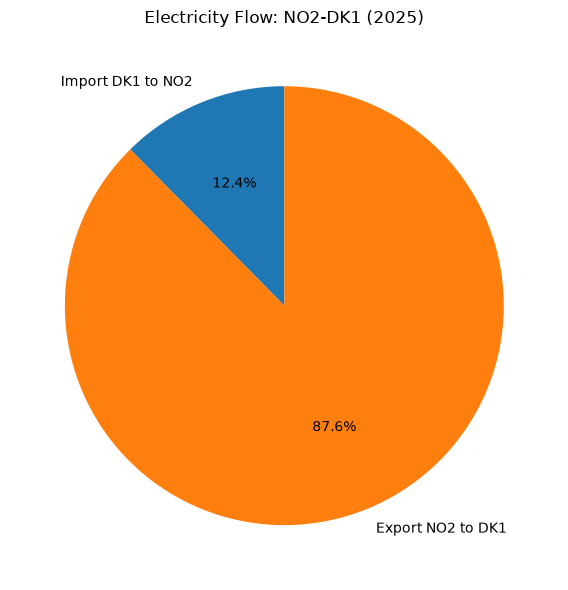

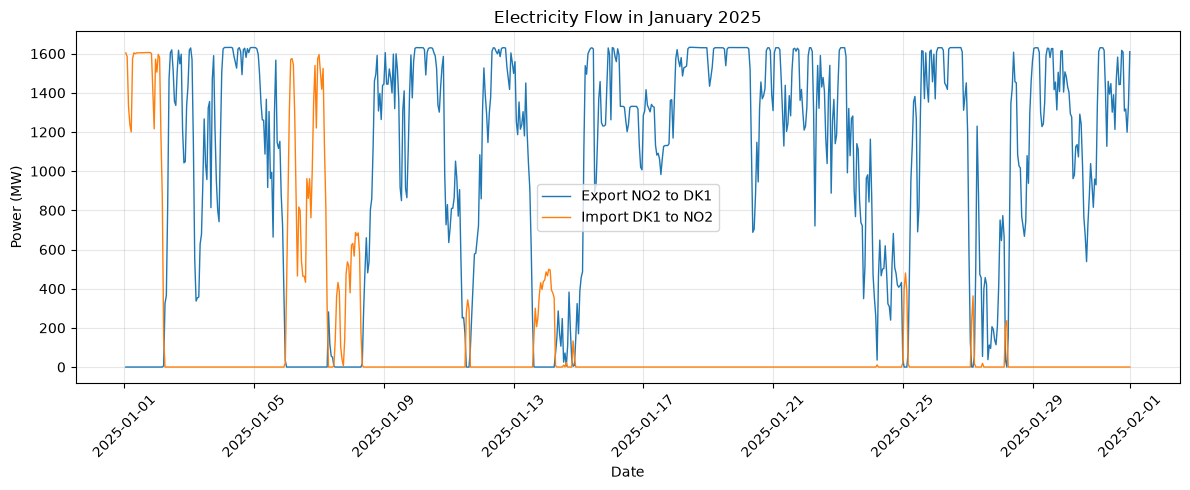

Spark data extraction and visualization completed.


In [20]:

import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import functions as F

# Select a connection and a complete calendar year
selected_connection = "NO2-DK1"
selected_year = 2025

# Extract the required columns and filter using Spark
selected_df = (
    cassandra_df
    .select(
        "connection",
        "direction",
        "observation_time",
        "power_mw",
        "energy_mwh"
    )
    .filter(F.col("connection") == selected_connection)
    .filter(F.year("observation_time") == selected_year)
)

# PIE CHART: total energy imported and exported during 2025
yearly_totals = (
    selected_df
    .groupBy("direction")
    .agg(F.sum("energy_mwh").alias("total_mwh"))
    .collect()
)

labels = [row["direction"] for row in yearly_totals]
values = [row["total_mwh"] for row in yearly_totals]

plt.figure(figsize=(7, 6))
plt.pie(
    values,
    labels=labels,
    autopct="%1.1f%%",
    startangle=90
)
plt.title(f"Electricity Flow: {selected_connection} ({selected_year})")
plt.tight_layout()
plt.show()

# LINE CHART: hourly or 15-minute power values in January
january_rows = (
    selected_df
    .filter(F.month("observation_time") == 1)
    .select("observation_time", "direction", "power_mw")
    .orderBy("observation_time")
    .collect()
)

january_pd = pd.DataFrame(
    [row.asDict() for row in january_rows]
)

plt.figure(figsize=(12, 5))

for direction, group in january_pd.groupby("direction"):
    plt.plot(
        group["observation_time"],
        group["power_mw"],
        label=direction,
        linewidth=1
    )

plt.title(f"Electricity Flow in January {selected_year}")
plt.xlabel("Date")
plt.ylabel("Power (MW)")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Spark data extraction and visualization completed.")


## 11. Storing Processed Data in MongoDB

This section transfers selected electricity flow data from
Cassandra through Apache Spark to MongoDB Atlas.

MongoDB will serve as the data source for the Streamlit application.

In [21]:

import os
from datetime import datetime, timezone
from dotenv import load_dotenv
from pymongo import MongoClient, UpdateOne
from pyspark.sql import functions as F

# Connect securely to MongoDB Atlas
load_dotenv(".env", override=True)

mongo_client = MongoClient(
    os.environ["MONGODB_URI"],
    serverSelectionTimeoutMS=10000
)

mongo_client.admin.command("ping")

# Select the database and collection
mongo_db = mongo_client["ind320"]
mongo_collection = mongo_db["cross_border_flows"]

# Extract 10 observations from Cassandra using Spark
sample_rows = (
    cassandra_df
    .select(
        "connection",
        "direction",
        "observation_time",
        "power_mw",
        "energy_mwh"
    )
    .orderBy("observation_time")
    .limit(10)
    .withColumn(
        "timestamp_utc",
        F.date_format(
            "observation_time",
            "yyyy-MM-dd'T'HH:mm:ss"
        )
    )
    .collect()
)

# Prepare MongoDB documents
operations = []

for row in sample_rows:
    timestamp = datetime.fromisoformat(
        row["timestamp_utc"]
    ).replace(tzinfo=timezone.utc)

    document = {
        "connection": row["connection"],
        "direction": row["direction"],
        "timestamp": timestamp,
        "year": timestamp.year,
        "month": timestamp.month,
        "power_mw": float(row["power_mw"]),
        "energy_mwh": float(row["energy_mwh"])
    }

    # Upsert prevents duplicates when rerunning the cell
    operations.append(
        UpdateOne(
            {
                "connection": document["connection"],
                "direction": document["direction"],
                "timestamp": document["timestamp"]
            },
            {"$set": document},
            upsert=True
        )
    )

result = mongo_collection.bulk_write(operations)

print("Successfully connected to MongoDB Atlas!")
print("New documents inserted:", result.upserted_count)
print("Existing documents updated:", result.modified_count)
print("Documents in collection:", mongo_collection.count_documents({}))

# Display an example without MongoDB's internal ID
example = mongo_collection.find_one({}, {"_id": 0})
print("\nExample document:")
print(example)


Successfully connected to MongoDB Atlas!
New documents inserted: 10
Existing documents updated: 0
Documents in collection: 10

Example document:
{'connection': 'NO2-DK1', 'direction': 'Import DK1 to NO2', 'timestamp': datetime.datetime(2024, 10, 12, 0, 0), 'energy_mwh': 0.0, 'month': 10, 'power_mw': 0.0, 'year': 2024}


In [22]:

from datetime import datetime, timezone
from pymongo import UpdateOne
from pyspark.sql import functions as F

# Create a unique index to prevent duplicate observations
mongo_collection.create_index(
    [("connection", 1), ("direction", 1), ("timestamp", 1)],
    unique=True
)

# Select the required columns from Cassandra using Spark
mongo_source_df = cassandra_df.select(
    "connection",
    "direction",
    "observation_time",
    "power_mw",
    "energy_mwh"
).withColumn(
    "timestamp_utc",
    F.date_format("observation_time", "yyyy-MM-dd'T'HH:mm:ss")
)

# Transfer data in batches to avoid loading everything into memory
batch = []
processed = 0
batch_size = 1000

for row in mongo_source_df.toLocalIterator():

    timestamp = datetime.fromisoformat(
        row["timestamp_utc"]
    ).replace(tzinfo=timezone.utc)

    document = {
        "connection": row["connection"],
        "direction": row["direction"],
        "timestamp": timestamp,
        "year": timestamp.year,
        "month": timestamp.month,
        "power_mw": float(row["power_mw"]),
        "energy_mwh": float(row["energy_mwh"])
    }

    batch.append(
        UpdateOne(
            {
                "connection": document["connection"],
                "direction": document["direction"],
                "timestamp": timestamp
            },
            {"$set": document},
            upsert=True
        )
    )

    if len(batch) >= batch_size:
        mongo_collection.bulk_write(batch, ordered=False)
        processed += len(batch)
        batch = []

        print(f"Processed {processed} observations")

# Insert any remaining observations
if batch:
    mongo_collection.bulk_write(batch, ordered=False)
    processed += len(batch)

print("\nTransfer completed!")
print("Observations processed:", processed)
print(
    "Documents in MongoDB:",
    mongo_collection.count_documents({})
)

print(
    "Matches Cassandra:",
    mongo_collection.count_documents({}) == cassandra_df.count()
)


Processed 1000 observations
Processed 2000 observations
Processed 3000 observations
Processed 4000 observations
Processed 5000 observations
Processed 6000 observations
Processed 7000 observations
Processed 8000 observations
Processed 9000 observations
Processed 10000 observations
Processed 11000 observations
Processed 12000 observations
Processed 13000 observations
Processed 14000 observations
Processed 15000 observations
Processed 16000 observations
Processed 17000 observations
Processed 18000 observations
Processed 19000 observations
Processed 20000 observations
Processed 21000 observations
Processed 22000 observations
Processed 23000 observations
Processed 24000 observations
Processed 25000 observations
Processed 26000 observations
Processed 27000 observations
Processed 28000 observations
Processed 29000 observations
Processed 30000 observations
Processed 31000 observations
Processed 32000 observations
Processed 33000 observations
Processed 34000 observations
Processed 35000 observa

## 12. Retrieving Reservoir Data from the NVE API

In [23]:

import requests
import pandas as pd

# Retrieve reservoir statistics directly from NVE
url = (
    "https://biapi.nve.no/magasinstatistikk/"
    "api/Magasinstatistikk/HentOffentligData"
)

response = requests.get(url, timeout=60)
print("HTTP status:", response.status_code)
response.raise_for_status()

# Convert the API response to a DataFrame
data = response.json()
df_nve = pd.DataFrame(data)

print("Number of rows:", len(df_nve))
print("Columns:", df_nve.columns.tolist())

if "omrType" in df_nve.columns:
    print("\nArea types:")
    print(df_nve["omrType"].value_counts())

display(df_nve.head())


HTTP status: 200
Number of rows: 14913
Columns: ['dato_Id', 'omrType', 'omrnr', 'iso_aar', 'iso_uke', 'fyllingsgrad', 'kapasitet_TWh', 'fylling_TWh', 'neste_Publiseringsdato', 'fyllingsgrad_forrige_uke', 'endring_fyllingsgrad']

Area types:
omrType
EL      8285
VASS    4971
NO      1657
Name: count, dtype: int64


,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
0,1995-09-03,EL,4,1995,35,0.944721,21.079208,19.913979,0001-01-01T00:00:00,0.936888,0.007833
1,2020-11-15,EL,1,2020,46,0.974361,6.003264,5.849344,2020-11-25T13:00:00,0.997406,-0.023046
2,2011-08-28,EL,4,2011,34,0.786499,21.079208,16.578772,0001-01-01T00:00:00,0.787193,-0.000694
3,1998-07-05,EL,3,1998,27,0.793969,8.920932,7.082947,0001-01-01T00:00:00,0.733812,0.060157
4,2011-03-27,EL,4,2011,12,0.300820,21.079208,6.341054,0001-01-01T00:00:00,0.311122,-0.010301


In [24]:

import pandas as pd
import requests
import streamlit as st

# Official NVE reservoir statistics API
NVE_URL = (
    "https://biapi.nve.no/magasinstatistikk/"
    "api/Magasinstatistikk/HentOffentligData"
)


@st.cache_data(ttl=3600)
def load_reservoir_data():
    """Download and prepare Norwegian reservoir data from NVE."""

    # Retrieve the dataset directly from the API
    response = requests.get(NVE_URL, timeout=60)
    response.raise_for_status()

    df = pd.DataFrame(response.json())

    # Rename Norwegian columns to descriptive English names
    df = df.rename(columns={
        "dato_Id": "date",
        "omrType": "area_type",
        "omrnr": "area",
        "iso_aar": "year",
        "iso_uke": "week",
        "fyllingsgrad": "fill_level",
        "kapasitet_TWh": "capacity_TWh",
        "fylling_TWh": "stored_energy_TWh",
        "neste_Publiseringsdato": "next_publication_date",
        "fyllingsgrad_forrige_uke": "fill_level_previous_week",
        "endring_fyllingsgrad": "change_in_fill_level"
    })

    # Convert and sort dates
    df["date"] = pd.to_datetime(df["date"], errors="coerce")

    df = df.dropna(subset=["date"])
    df = df.sort_values(
        ["area_type", "area", "date"]
    ).reset_index(drop=True)

    return df


2026-10-12 23:30:36.529 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


# ------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

## XX. Development log

The Streamlit application was developed to make the reservoir data more interactive and easier to explore. The application was divided into four separate pages, with a front page that provides navigation to the other pages. The reservoir dataset is read from the local CSV file, and caching is used so that the data does not have to be loaded again every time the user interacts with the application.

On the second page, the imported data is presented in a table. A row wise LineChartColumn is used to provide a small visualization of the first month of each data series. This gives the user a quick overview of the different variables without having to open a separate plot for each one.
The third page contains the main interactive visualization. A selectbox allows the user to choose one numerical variable or display all variables together. A selection slider is also included so that the user can choose which months to display, with the first month selected by default. During development, I tested the different selections to make sure that the plot updated correctly and that the dates were displayed in chronological order.

Finally, the Streamlit project was connected to a public GitHub repository and deployed online using Streamlit Community Cloud. Working with Streamlit gave me experience with turning a local data analysis into an interactive web application. It also showed me how the structure of the data and the choices made during preprocessing in the Jupyter Notebook affect how the data can later be presented in an application.

## XX. AI usage

AI tools were used as support during the development of this project. ChatGPT was used to help interpret the assignment requirements, structure the Jupyter Notebook, and troubleshoot errors.

The suggested code was tested and adjusted during development. For example, the initial visualizations connected observations from different reservoir areas, which resulted in misleading plots. The plotting approach was therefore changed to separate the reservoir areas. AI was also used to suggest an approach for normalizing variables with different scales before plotting them together.

The final implementation was reviewed and tested in the local development environment.